# Exercise 2: k-means clustering

Same images and embeddings as Exercise 1, layer 3 using five clusters.

## 1. Load the dataset

In [66]:
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import hf_hub_download
from sklearn.cluster import KMeans

DATA = "blanchon/UC_Merced"

ds = load_dataset(DATA, split="train")
class_names = ds.features["label"].names
labels = np.array(ds["label"])

print(f"{len(ds)} images, {len(class_names)} classes")

2100 images, 21 classes


## 2. Embeddings

In [67]:
order = np.asarray(sorted(range(len(ds)), key=lambda i: (class_names[labels[i]], i)))
y_all = labels[order] + 1                      # 1-based, as in the embeddings

rng = np.random.default_rng(0)
train_idx, test_idx = [], []
for label in range(1, len(class_names) + 1):
    idx = np.where(y_all == label)[0]
    rng.shuffle(idx)
    n_test = max(1, int(round(len(idx) * 0.2)))
    test_idx += list(idx[:n_test])
    train_idx += list(idx[n_test:])

train_idx, test_idx = np.asarray(train_idx), np.asarray(test_idx)

print(f"train {len(train_idx)} / test {len(test_idx)}")

train 1680 / test 420


## 3. Align the training images

In [68]:
def to_rgb(row):
    im = row["image"].convert("RGB")
    if im.size != (256, 256):
        im = im.resize((256, 256))
    return np.asarray(im)

X_train_rgb = np.stack([to_rgb(ds[int(i)]) for i in order[train_idx]])
y_train = y_all[train_idx]

print(X_train_rgb.shape, y_train.shape)

(1680, 256, 256, 3) (1680,)


## 4. Load the embeddings

In [69]:
REPO = "MustafaArikan/vit_embeddings_uc_merced_layers"
path = hf_hub_download(REPO, "vit_embeddings_uc_merced_layers.npz", repo_type="dataset")
d = np.load(path)

LAYER = 3
E = d[f"E_train_l{LAYER}"]

print(E.shape)

(1680, 768)


## 5. k-means, 5 clusters

In [70]:
K = 5

km = KMeans(n_clusters=K, n_init="auto", random_state=1).fit(E)
clusters = km.labels_

print("cluster sizes:", np.bincount(clusters, minlength=K))

cluster sizes: [347 380 324  77 552]


## 6. TODO: Visualize cluster number 3 and describe it, is it useful?

* Yes, the cluster is useful, as almost every image in the cluster belongs to the same label and they all look very similar.

In [71]:
from collections import Counter

def visualize_clusters(target, clusters, matrix:bool = True):
   
    cluster_indices = np.where(clusters == target)[0]

    # describe how often each label appears
    labels_in_cluster = [class_names[y_train[i] - 1] for i in cluster_indices]    
    label_counts = Counter(labels_in_cluster)
    print(f"--- Label Breakdown for Cluster {target} ({len(cluster_indices)} total images) ---")
    for label, count in label_counts.most_common():
        print(f"{label:20}: {count}")


    if (matrix):
        # select 100 images randomly, to get a view on the cluster
        num_samples = min(100, len(cluster_indices))
        sample_idx = np.random.choice(cluster_indices, size=num_samples, replace=False)

        fig, axes = plt.subplots(10, 10, figsize=(12, 12))
        axes = axes.flatten()

        for i, ax in enumerate(axes):
            if i < num_samples:
                ax.imshow(X_train_rgb[sample_idx[i]])        
            ax.axis('off') 
    
        plt.subplots_adjust(wspace=0.05, hspace=0.05)
        plt.show()

--- Label Breakdown for Cluster 3 (77 total images) ---
chaparral           : 74
agricultural        : 3


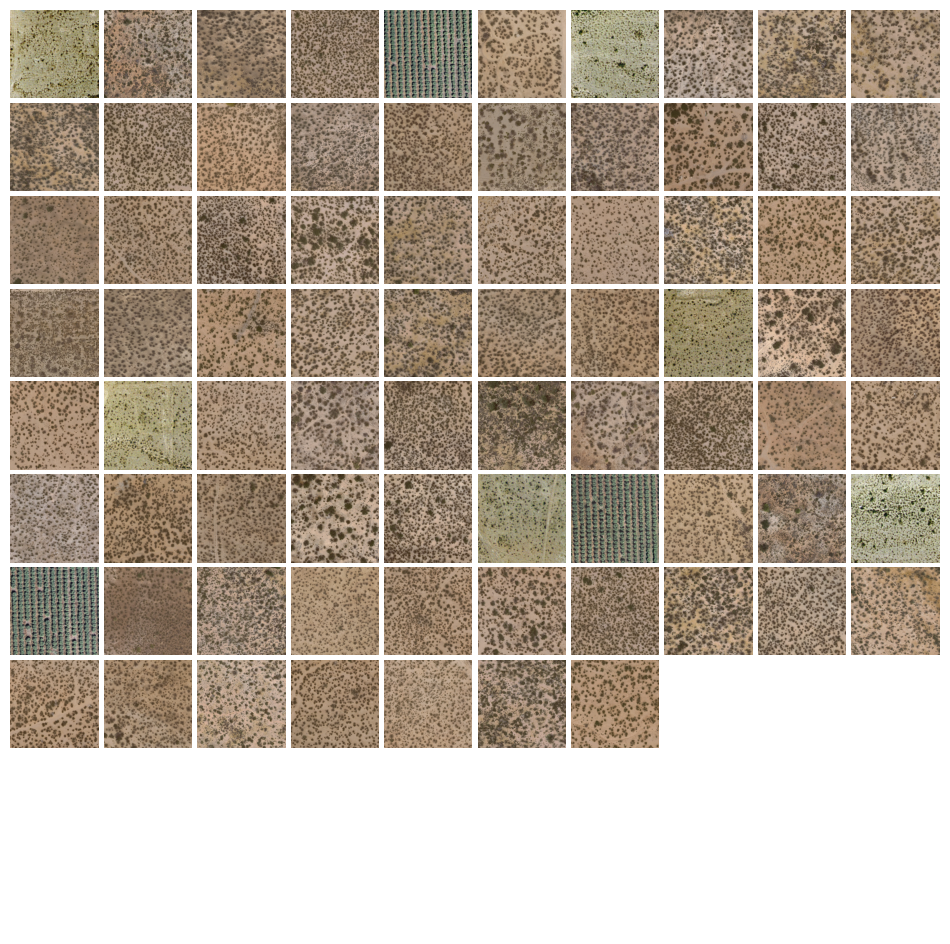

In [72]:
visualize_clusters(3, clusters)

## 7. TODO: is there another cluster that is useful from the 5

* Cluster 2 can also be considered useful

--- Label Breakdown for Cluster 0 (347 total images) ---
forest              : 43
buildings           : 41
harbor              : 41
parkinglot          : 26
storagetanks        : 25
intersection        : 22
overpass            : 22
denseresidential    : 19
airplane            : 17
freeway             : 17
river               : 17
mobilehomepark      : 16
sparseresidential   : 12
mediumresidential   : 10
baseballdiamond     : 8
tenniscourt         : 7
runway              : 3
golfcourse          : 1


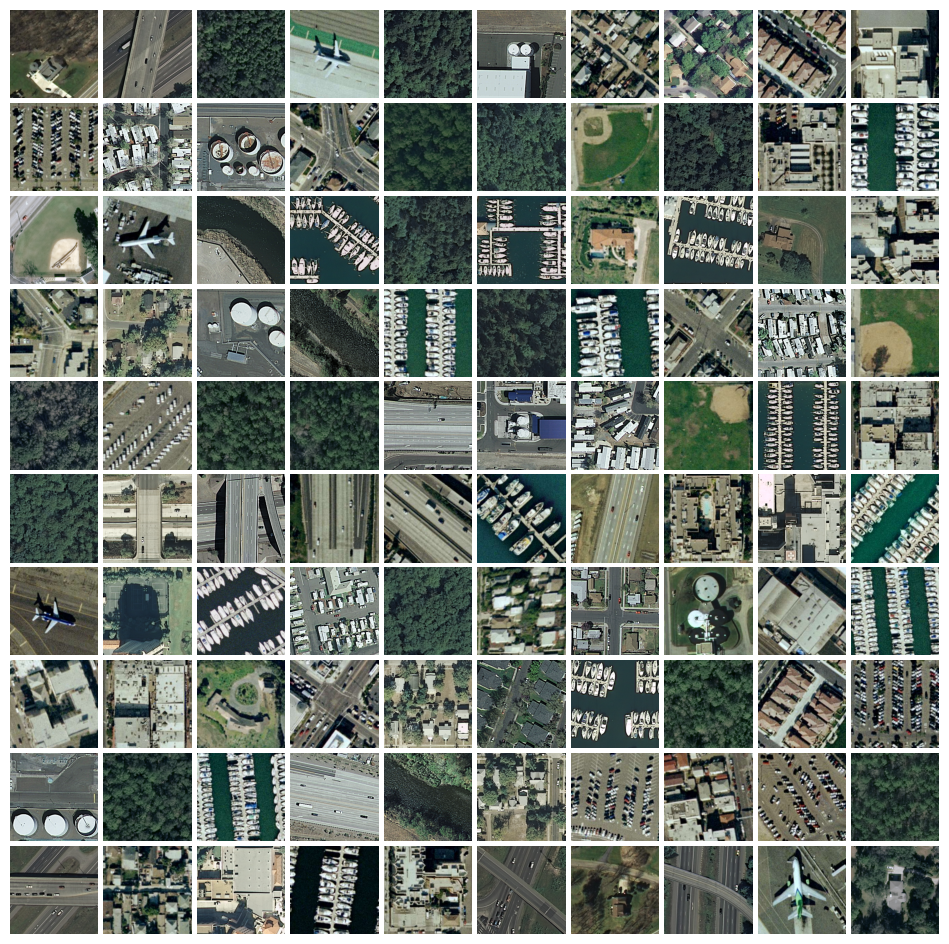

In [73]:
visualize_clusters(0, clusters)

There are some patterns but in the end --> not useful

--- Label Breakdown for Cluster 1 (380 total images) ---
tenniscourt         : 50
denseresidential    : 42
mobilehomepark      : 38
airplane            : 29
intersection        : 25
sparseresidential   : 25
golfcourse          : 23
buildings           : 21
mediumresidential   : 21
baseballdiamond     : 20
freeway             : 19
parkinglot          : 17
runway              : 14
river               : 13
overpass            : 11
forest              : 7
storagetanks        : 3
harbor              : 2


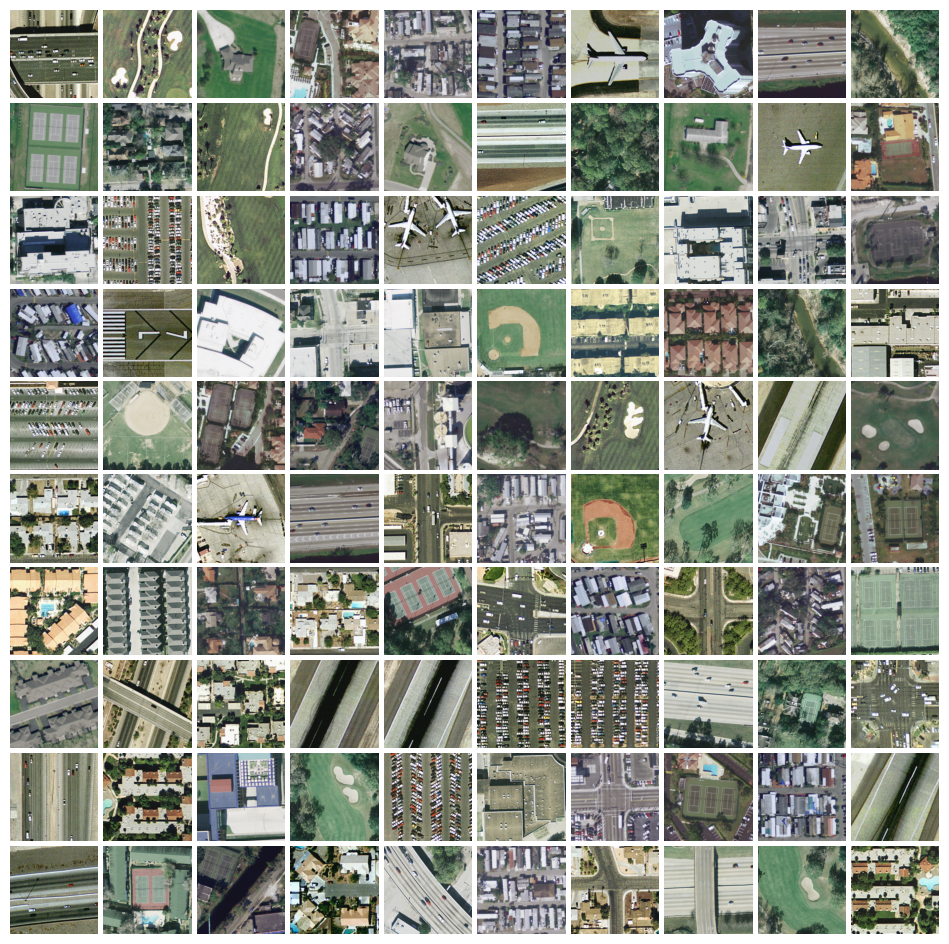

In [74]:
visualize_clusters(1, clusters)

Cluster is completely random --> not useful

--- Label Breakdown for Cluster 2 (324 total images) ---
beach               : 78
agricultural        : 76
golfcourse          : 42
runway              : 38
baseballdiamond     : 33
river               : 20
forest              : 19
freeway             : 8
chaparral           : 6
storagetanks        : 2
overpass            : 1
sparseresidential   : 1


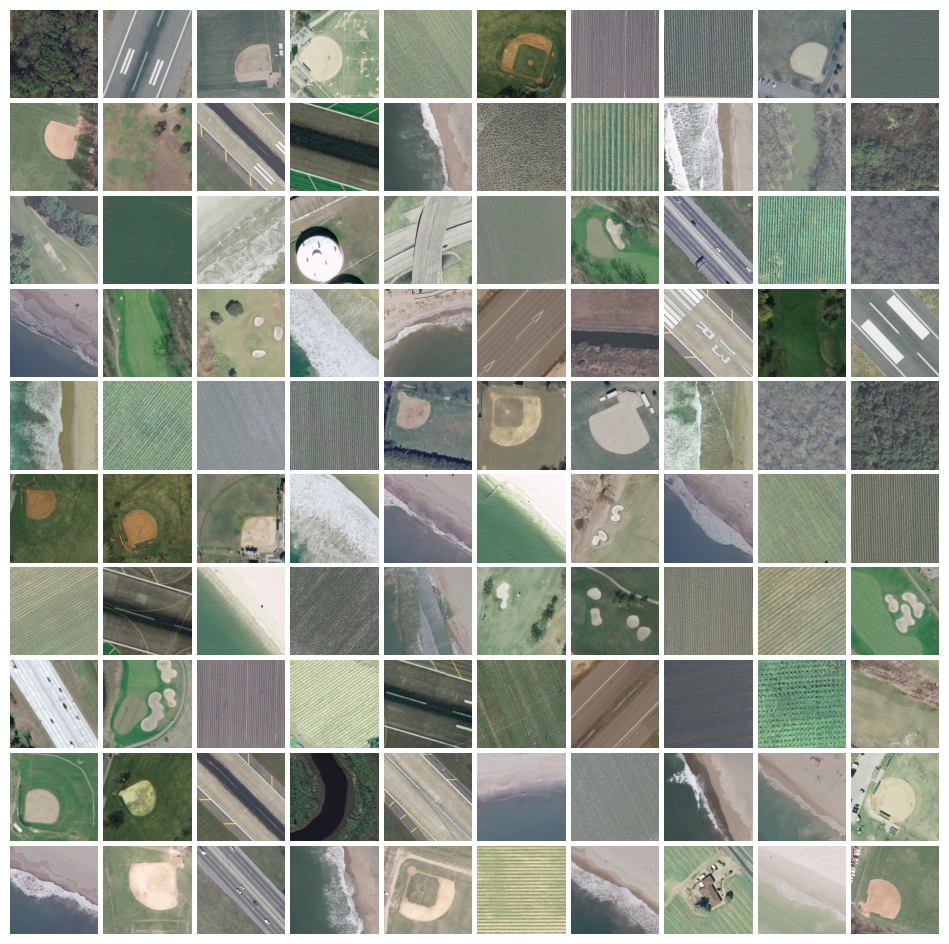

In [75]:
visualize_clusters(2, clusters)

The images have a good similarity --> useful

--- Label Breakdown for Cluster 4 (552 total images) ---
storagetanks        : 50
mediumresidential   : 49
overpass            : 46
sparseresidential   : 42
harbor              : 37
parkinglot          : 37
freeway             : 36
airplane            : 34
intersection        : 33
river               : 30
mobilehomepark      : 26
runway              : 25
tenniscourt         : 23
baseballdiamond     : 19
denseresidential    : 19
buildings           : 18
golfcourse          : 14
forest              : 11
beach               : 2
agricultural        : 1


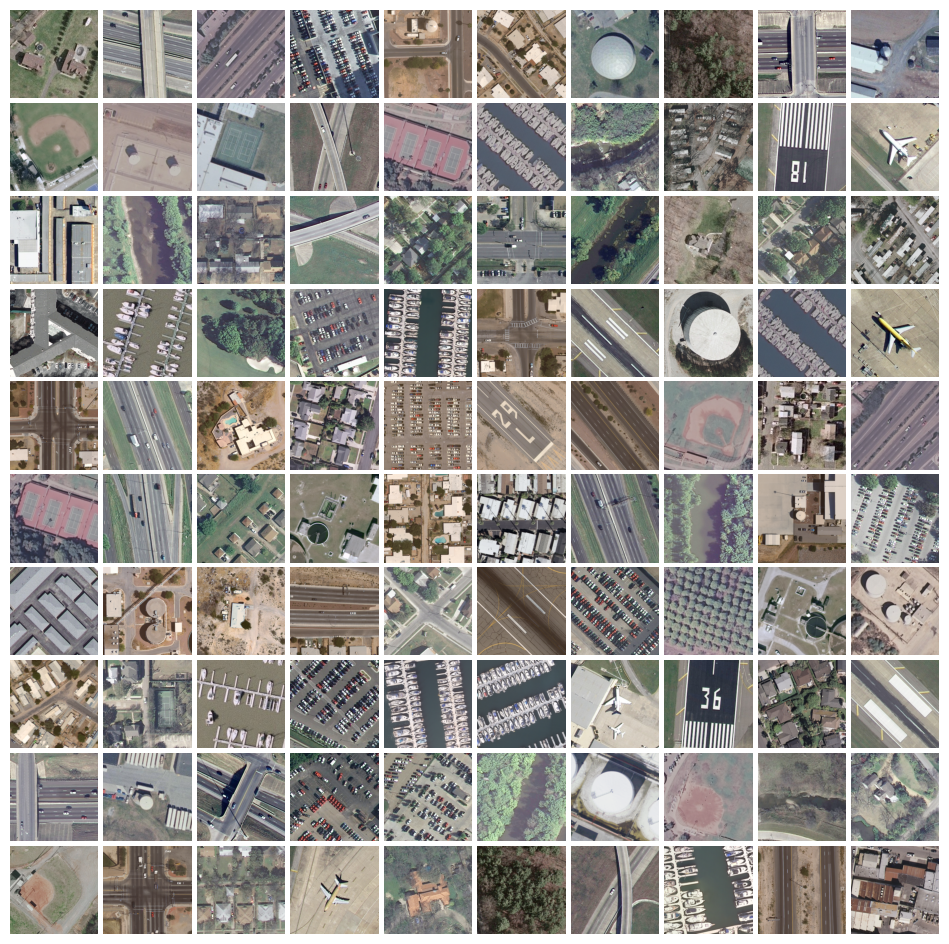

In [76]:
visualize_clusters(4, clusters)

Not really a similarity --> not useful

## 8. TODO: repeat k-means with 10 and 15 clusters, and with different seeds. Does the result change? Does it get more useful? What would a useful cluster even look like, and why?

* A useful cluster has images that are from the same label or have similar patterns (look familiar)

* Based on the labels the quality of the clusters gets better, the clusters still contain a lot of images with different labels but the labels and therfore the images are more similar than before. So in the end we get a good imporvement. The clusters get more useful.

In [79]:
cluster_sizes = [10,15]
seeds = [16, 42, 124]

for seed in seeds:
    for cluster_size in cluster_sizes:
        km = KMeans(n_clusters=cluster_size, n_init="auto", random_state=seed).fit(E)
        clusters_8 = km.labels_
        print(f"----- Clusters {cluster_size}, Seed {seed} -----")
        for i in range(cluster_size):
            visualize_clusters(i, clusters_8, False)




----- Clusters 10, Seed 16 -----
--- Label Breakdown for Cluster 0 (191 total images) ---
baseballdiamond     : 48
golfcourse          : 35
sparseresidential   : 29
beach               : 19
tenniscourt         : 18
river               : 14
runway              : 8
freeway             : 5
intersection        : 4
overpass            : 4
airplane            : 2
denseresidential    : 1
forest              : 1
mediumresidential   : 1
mobilehomepark      : 1
storagetanks        : 1
--- Label Breakdown for Cluster 1 (126 total images) ---
airplane            : 29
denseresidential    : 14
parkinglot          : 14
runway              : 13
intersection        : 12
freeway             : 11
overpass            : 8
golfcourse          : 7
mediumresidential   : 7
buildings           : 5
chaparral           : 3
tenniscourt         : 2
baseballdiamond     : 1
--- Label Breakdown for Cluster 2 (356 total images) ---
beach               : 59
golfcourse          : 37
river               : 35
runway       